#  Customer Support Analytics & CSAT Prediction

##### **Project Type**    - Classification


# **Project Summary -**

Customer satisfaction plays a critical role in the success of any e-commerce platform. Leading e-commerce companies receive thousands of customer support requests daily through different service channels. Ensuring that customers receive timely and effective support is essential for maintaining high satisfaction levels and building long-term customer loyalty.

This project aims to analyze customer service interaction data and build a machine learning model to predict customer satisfaction using the Customer Satisfaction Score (CSAT). The dataset contains detailed information about customer interactions with support agents, including communication channels, issue categories, response times, product categories, agent information, and customer remarks.

The objective of this project is to identify the key factors that influence customer satisfaction and build a predictive classification model that can determine whether a customer interaction will result in a high or low satisfaction score. By analyzing patterns in the data, the model can help organizations better understand the drivers of customer satisfaction and identify areas where service performance can be improved.

The project begins with exploratory data analysis (EDA) to understand the structure of the dataset, identify missing values, and analyze the relationships between variables. Visualizations are used to examine trends in customer satisfaction across different service channels, product categories, and agent performance. Data cleaning and preprocessing steps are then performed to handle missing values, convert date columns, and encode categorical variables.

Feature engineering techniques are applied to extract useful information from the dataset, such as calculating response times between issue reporting and agent responses. Additionally, text data from customer remarks can be analyzed to capture sentiment and further improve prediction performance.

Several machine learning classification algorithms are implemented to predict the CSAT score, including Logistic Regression, Decision Tree, and Random Forest. These models are trained on historical customer service interaction data and evaluated using performance metrics such as accuracy, precision, recall, and F1-score.

The final model helps identify important features that influence customer satisfaction, enabling businesses to improve their support strategies. Insights from this analysis can assist e-commerce businesses in optimizing agent performance, reducing response times, and improving overall customer experience.

This project demonstrates the use of data analysis, feature engineering, and machine learning techniques to solve real-world business problems in the customer service domain.

# **Problem Statement**


### Problem Statement

In the competitive e-commerce industry, customer satisfaction is a key factor that determines customer retention and brand loyalty. E-commerce platforms handle a large number of customer service interactions every day across multiple channels such as calls, emails, and chats. Understanding how these interactions affect customer satisfaction is important for improving service quality.

The dataset contains detailed records of customer service interactions, including information about communication channels, issue categories, response times, product details, customer remarks, and support agent details. Each interaction is associated with a CSAT (Customer Satisfaction) score, which indicates the level of satisfaction experienced by the customer.

The goal of this project is to build a machine learning classification model that can predict the CSAT score based on various factors related to customer support interactions. By analyzing patterns in the dataset, the model aims to identify the most important factors that influence customer satisfaction.

The insights generated from this project can help e-commerce businesses improve customer support performance, optimize response times, enhance agent training programs, and ultimately improve overall customer satisfaction.

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries

# Data Handling
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ML Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

### Dataset Loading

In [2]:
# Load Dataset
df=pd.read_csv('/content/Customer_support_data.csv')

### Dataset First View

In [3]:
# Dataset First Look
df.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
df.shape


(85907, 20)

### Dataset Information

In [5]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
df.duplicated().sum()

np.int64(0)

#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
df.isnull().sum()


,0
Unique id,0
channel_name,0
category,0
Sub-category,0
Customer Remarks,57165
Order_id,18232
order_date_time,68693
Issue_reported at,0
issue_responded,0
Survey_response_Date,0


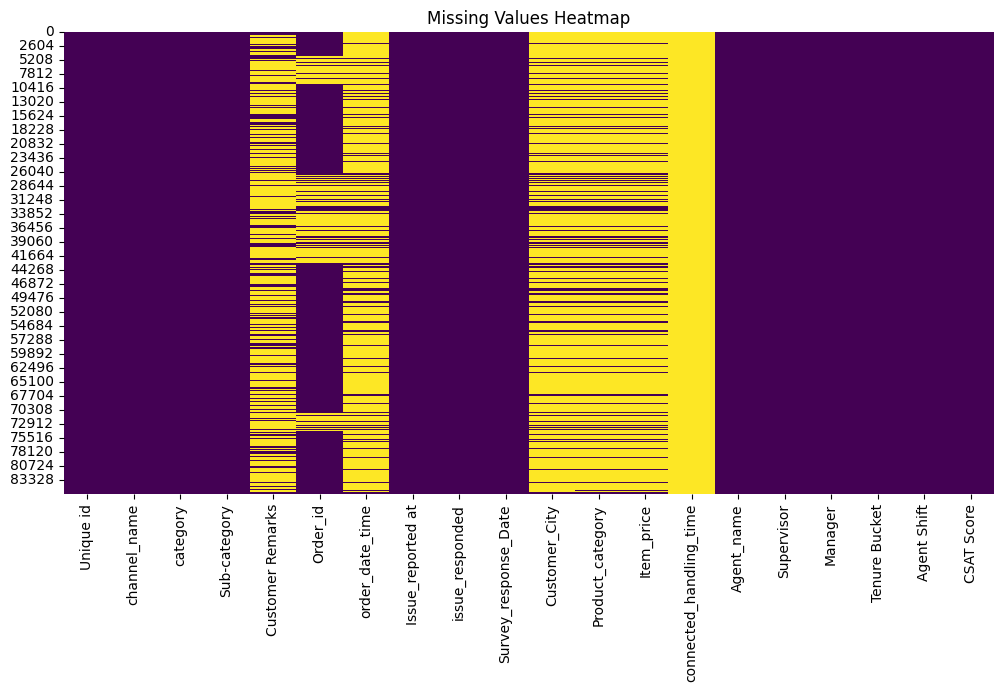

In [8]:
# Visualizing the missing values
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(),cbar=False,cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

### What did you know about your dataset?

The dataset contains information related to customer service interactions and customer satisfaction. It includes details such as the communication channel used by the customer, issue category, sub-category, customer remarks, order details, product information, agent details, and the customer satisfaction score (CSAT).

The dataset consists of **85,907 rows and 20 columns**, where each row represents a single customer support interaction. Most of the columns in the dataset are **categorical variables (object data type)**, such as channel name, category, sub-category, customer city, and agent information. The dataset also contains a few **numerical variables**, including item price, connected handling time, and CSAT score.

During the initial data exploration, it was observed that some columns contain **missing values**, particularly **Customer Remarks, Order_id, order_date_time, Customer_City, Product_category, Item_price, and connected_handling_time**. The column **connected_handling_time** has a very high number of missing values compared to the total dataset size.

Additionally, it was confirmed that there are **no duplicate records** in the dataset, indicating that each row represents a unique customer interaction.

The **CSAT Score column represents the customer satisfaction rating** and will be used as the **target variable** for building the classification model in this project.


## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
df.columns

Index(['Unique id', 'channel_name', 'category', 'Sub-category',
       'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at',
       'issue_responded', 'Survey_response_Date', 'Customer_City',
       'Product_category', 'Item_price', 'connected_handling_time',
       'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift',
       'CSAT Score'],
      dtype='object')

In [10]:
# Dataset Describe
df.describe()


,Item_price,connected_handling_time,CSAT Score
count,17206.000000,242.000000,85907.000000
mean,5660.774846,462.400826,4.242157
std,12825.728411,246.295037,1.378903
min,0.000000,0.000000,1.000000
25%,392.000000,293.000000,4.000000
50%,979.000000,427.000000,5.000000
75%,2699.750000,592.250000,5.000000
max,164999.000000,1986.000000,5.000000


### Variables Description

## Dataset Columns

The dataset contains **20 variables** that describe customer service interactions, product information, support agent details, and customer satisfaction scores.

**Unique id** – A unique identifier assigned to each customer interaction.

**channel_name** – The communication channel through which the customer contacted support (for example, inbound or outcall).

**category** – The main category of the issue raised by the customer.

**Sub-category** – A more specific classification of the issue under the main category.

**Customer Remarks** – Text feedback or comments given by the customer regarding their issue or experience.

**Order_id** – The unique identification number associated with the customer’s order.

**order_date_time** – The date and time when the order was placed.

**Issue_reported at** – The date and time when the customer reported the issue.

**issue_responded** – The time when the support agent responded to the customer’s issue.

**Survey_response_Date** – The date when the customer submitted the satisfaction survey.

**Customer_City** – The city from which the customer raised the request.

**Product_category** – The category of the product related to the customer’s issue.

**Item_price** – The price of the product associated with the order.

**connected_handling_time** – The amount of time spent by the support agent handling the issue.

**Agent_name** – The name of the customer support agent who handled the interaction.

**Supervisor** – The supervisor responsible for managing the support agent.

**Manager** – The manager overseeing the support team.

**Tenure Bucket** – The experience level of the agent based on their time with the company.

**Agent Shift** – The working shift of the agent when the issue was handled (for example, Morning or Evening).

**CSAT Score** – The customer satisfaction score given by the customer after the interaction. This score ranges from **1 to 5** and is used as the **target variable** in the machine learning model.


### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for col in df.columns:
    print(col, ":", df[col].nunique())

Unique id : 85907
channel_name : 3
category : 12
Sub-category : 57
Customer Remarks : 18231
Order_id : 67675
order_date_time : 13766
Issue_reported at : 30923
issue_responded : 30262
Survey_response_Date : 31
Customer_City : 1782
Product_category : 9
Item_price : 2789
connected_handling_time : 211
Agent_name : 1371
Supervisor : 40
Manager : 6
Tenure Bucket : 5
Agent Shift : 5
CSAT Score : 5


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.

In [13]:
# Create a copy of the dataset
df_copy = df.copy()

#### handling missing values

In [14]:
# Check missing values
df_copy.isnull().sum()

,0
Unique id,0
channel_name,0
category,0
Sub-category,0
Customer Remarks,57165
Order_id,18232
order_date_time,68693
Issue_reported at,0
issue_responded,0
Survey_response_Date,0


In [15]:
# Drop column with very high missing values
df_copy.drop('connected_handling_time', axis=1, inplace=True)

In [16]:
# Fill missing values with appropriate methods

In [17]:
df_copy.drop('order_date_time',axis=1,inplace=True)

In [18]:
df_copy['Customer_City'].fillna('Unknown',inplace=True)

In [19]:
df_copy['Product_category'].fillna('Unknown',inplace=True)

In [20]:
df_copy['Item_price'].fillna(df_copy['Item_price'].median(),inplace=True)

In [21]:
df_copy['Customer Remarks'].fillna('No Remark',inplace=True)

In [22]:
df_copy['Order_id'].fillna('Unknown',inplace=True)

#### handling datetime columns

In [23]:
# Convert datetime columns
df_copy['Issue_reported at'] = pd.to_datetime(df_copy['Issue_reported at'], dayfirst=True, errors='coerce')
df_copy['issue_responded'] = pd.to_datetime(df_copy['issue_responded'], dayfirst=True, errors='coerce')
df_copy['Survey_response_Date'] = pd.to_datetime(df_copy['Survey_response_Date'], format='%d-%b-%y', errors='coerce')

####handling duplicates

In [24]:
# Check duplicate rows
df_copy.duplicated().sum()

np.int64(0)

In [25]:
# Drop duplicates if present
df_copy.drop_duplicates(inplace=True)

#### handling outliers

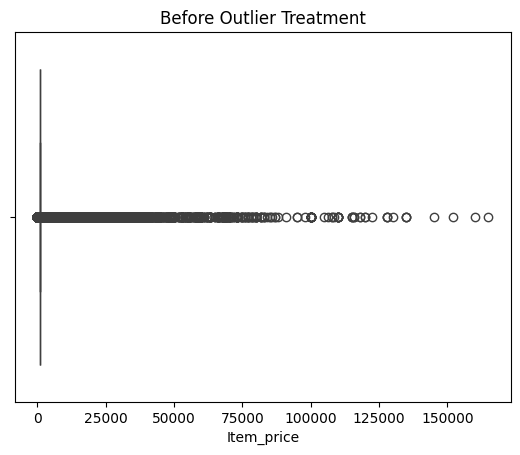

In [26]:
# Visualize outliers before treatment
sns.boxplot(x=df_copy['Item_price'])
plt.title('Before Outlier Treatment')
plt.show()

In [27]:
# Calculate IQR and remove outliers
Q1 = df_copy['Item_price'].quantile(0.25)
Q3 = df_copy['Item_price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_copy = df_copy[
    (df_copy['Item_price'] >= lower_bound) &
    (df_copy['Item_price'] <= upper_bound)
]

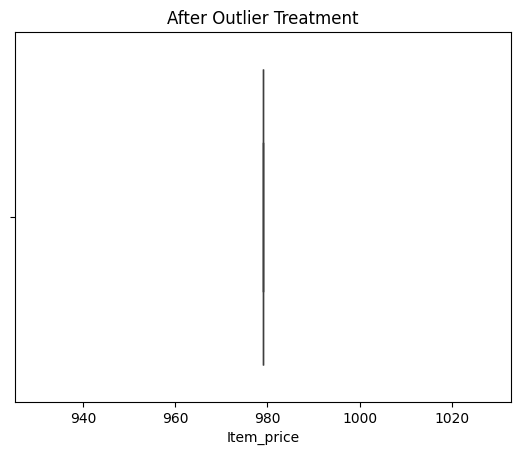

In [28]:
# Visualize after outlier removal
sns.boxplot(x=df_copy['Item_price'])
plt.title('After Outlier Treatment')
plt.show()

#### final check

In [29]:
# Check remaining missing values
df_copy.isnull().sum()

,0
Unique id,0
channel_name,0
category,0
Sub-category,0
Customer Remarks,0
Order_id,0
Issue_reported at,0
issue_responded,0
Survey_response_Date,0
Customer_City,0


In [30]:
# Check dataset structure and datatypes
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 68708 entries, 0 to 85906
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Unique id             68708 non-null  object        
 1   channel_name          68708 non-null  object        
 2   category              68708 non-null  object        
 3   Sub-category          68708 non-null  object        
 4   Customer Remarks      68708 non-null  object        
 5   Order_id              68708 non-null  object        
 6   Issue_reported at     68708 non-null  datetime64[ns]
 7   issue_responded       68708 non-null  datetime64[ns]
 8   Survey_response_Date  68708 non-null  datetime64[ns]
 9   Customer_City         68708 non-null  object        
 10  Product_category      68708 non-null  object        
 11  Item_price            68708 non-null  float64       
 12  Agent_name            68708 non-null  object        
 13  Supervisor           

In [31]:
# Check final shape
df_copy.shape

(68708, 18)

### What all manipulations have you done and insights you found?

## 🔹 Data Manipulations Performed

Several data preprocessing and cleaning steps were performed to prepare the dataset for analysis and modeling:

* **Handled Missing Values:**
  Columns with extremely high missing values such as `connected_handling_time` and `order_date_time` were dropped.
  Remaining missing values were treated using appropriate strategies:

  * Categorical variables like `Customer_City` and `Product_category` were filled with `'Unknown'`
  * `Customer Remarks` was filled with `'No Remark'`
  * Numerical column `Item_price` was imputed using the median

* **Datetime Conversion:**
  Columns such as `Issue_reported at`, `issue_responded`, and `Survey_response_Date` were converted into datetime format to enable time-based analysis.

* **Duplicate Handling:**
  The dataset was checked for duplicate records and no duplicates were found.

* **Outlier Treatment:**
  Outliers in the `Item_price` column were detected using boxplots and handled using the IQR method to remove extreme values and reduce skewness.

* **Data Validation:**
  Final checks were performed using `.info()` and `.isnull().sum()` to ensure data consistency and completeness.

---

## 🔹 Key Insights from Data Wrangling

* A significant portion of the dataset contained **missing values**, especially in columns related to order details and product information, indicating incomplete customer interaction records.

* The `Item_price` column showed **high variability and extreme values**, suggesting the presence of both low-cost and high-value products.

* The `CSAT Score` is a **bounded variable (1–5)** and does not require outlier treatment, as all values are valid ratings.

* The dataset contains **multiple categorical variables** such as channel, category, and agent details, which will be useful for further analysis.

* Datetime conversion enables creation of **time-based features**, such as response time, which may significantly impact customer satisfaction.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

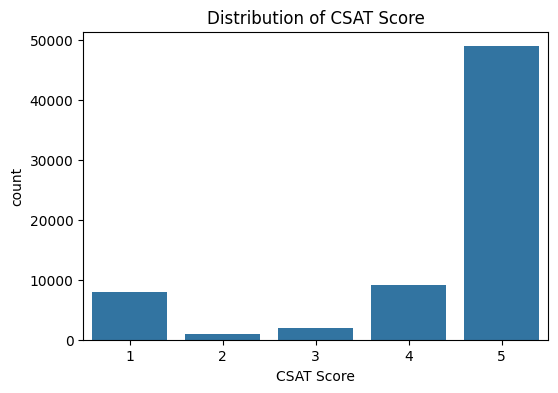

In [32]:
# Chart - 1 visualization code
# CSAT Score Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='CSAT Score', data=df_copy)
plt.title("Distribution of CSAT Score")
plt.show()

##### 1. Why did you pick the specific chart?

A countplot was chosen because CSAT Score is a categorical variable, and this chart effectively shows the frequency distribution of each rating level, making it easy to understand customer satisfaction patterns.

##### 2. What is/are the insight(s) found from the chart?

The majority of customers have given a rating of 5, followed by 4, indicating that most customers are highly satisfied. Very few customers have given low ratings (1 or 2), suggesting that negative experiences are relatively rare.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights indicate a positive business impact, as the majority of customers have given high ratings (4 and 5), reflecting strong overall customer satisfaction and good service quality.

However, there are also signs of potential negative impact, as a small proportion of customers have given low ratings (1 and 2). These low scores suggest that some customers faced poor experiences, which could lead to customer dissatisfaction, negative word-of-mouth, and possible loss of customers if not addressed.

#### Chart - 2

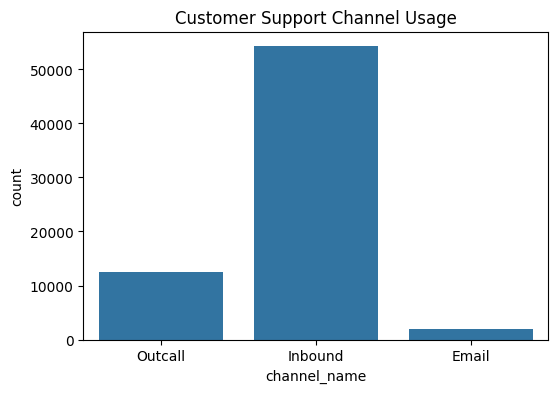

In [33]:
# Chart - 2 visualization code
# Channel Usage Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='channel_name', data=df_copy)
plt.title("Customer Support Channel Usage")
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is used because channel_name is a categorical variable, and this chart helps to easily compare the frequency of usage across different customer support channels.

##### 2. What is/are the insight(s) found from the chart?

* The Inbound channel is used the most by customers.

* Outcall has moderate usage.

* Email is the least preferred channel.

This shows that customers prefer direct and immediate communication methods over slower channels like email.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this insight can create a positive business impact by helping the company focus more resources on the inbound channel (like improving call handling and reducing wait time), which is the most used.

However, there is a potential negative impact as well. The very low usage of email suggests that customers may find it slow or ineffective. If not improved, it could lead to poor customer experience for users who prefer non-calling options.

#### Chart - 3

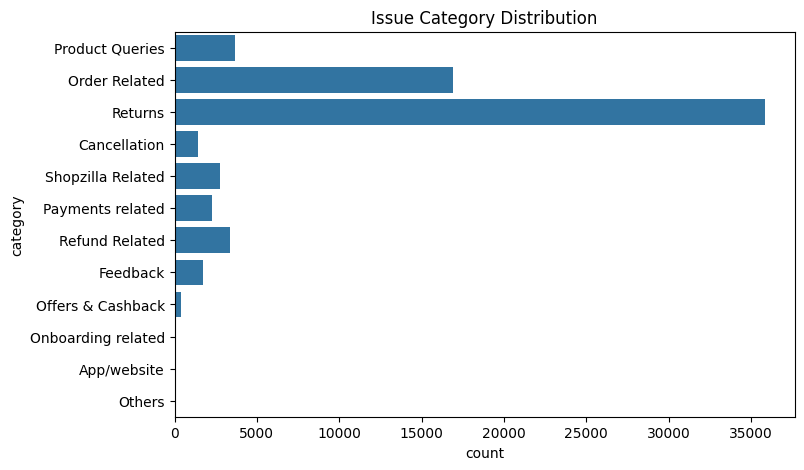

In [34]:
# Chart - 3 visualization code
# Issue Category Distribution
plt.figure(figsize=(8,5))
sns.countplot(y='category', data=df_copy)
plt.title("Issue Category Distribution")
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is used because category is a categorical variable, and this chart helps to compare the frequency of different issue types clearly.

##### 2. What is/are the insight(s) found from the chart?

* Returns is the most common issue category by a large margin.

* Order Related issues are the second highest.

* Categories like Cancellation, Payments, Refunds, Feedback have relatively lower counts.

This indicates that product returns are a major concern area.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can create a positive business impact by helping the business focus on reducing return-related issues (e.g., improving product quality, descriptions, or delivery accuracy).

However, there is also a negative growth indicator:
The high number of return issues suggests customer dissatisfaction with products or expectations mismatch, which can increase operational costs and reduce profitability if not addressed.

#### Chart - 4

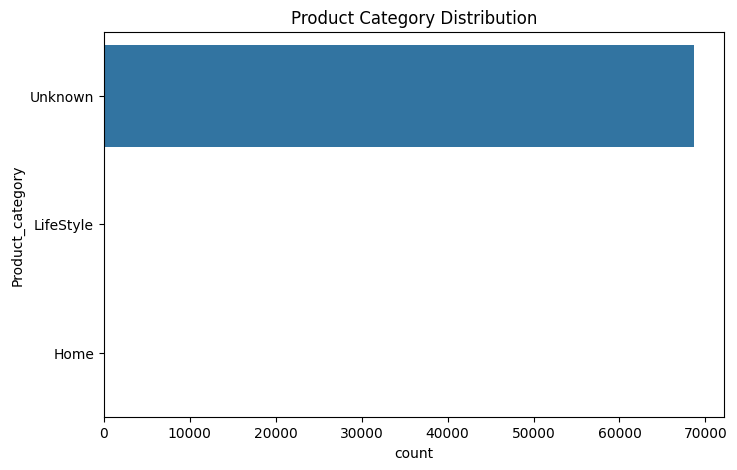

In [35]:
# Chart - 4 visualization code
# Product Category Distribution
plt.figure(figsize=(8,5))
sns.countplot(y='Product_category', data=df_copy)
plt.title("Product Category Distribution")
plt.show()

##### 1. Why did you pick the specific chart?

A countplot is used because Product_category is a categorical variable, and this chart clearly shows the frequency distribution of each category. It helps in understanding which product categories are most common in the dataset.

##### 2. What is/are the insight(s) found from the chart?

* A very large portion of data falls under the “Unknown” category.

* Other categories like Home and Lifestyle have very low representation.

* This indicates that product category information is missing for most records.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impact:

* Highlights a data quality issue, which is critical for business decisions.

* Improving product categorization can lead to better analysis, targeting, and customer insights.

Negative Insight (Important):

* Since most values are “Unknown”, it can lead to misleading analysis and poor decision-making.

* Lack of proper product classification may affect personalization, marketing strategies, and issue resolution efficiency.

#### Chart - 5

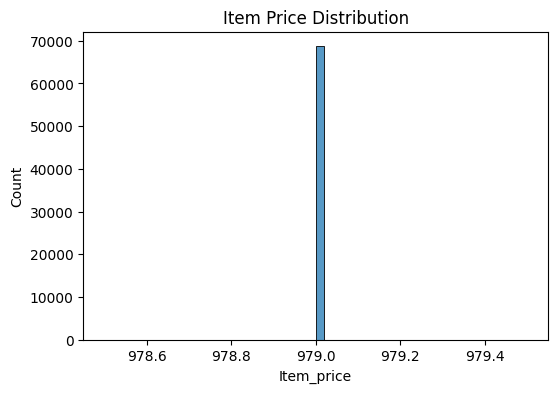

In [36]:
# Chart - 5 visualization code
# Item Price Distribution
plt.figure(figsize=(6,4))
sns.histplot(df_copy['Item_price'], bins=50)
plt.title("Item Price Distribution")
plt.show()

##### 1. Why did you pick the specific chart?

A histogram is used because Item_price is a numerical variable. It helps in understanding the distribution, spread, and concentration of price values.

##### 2. What is/are the insight(s) found from the chart?

* Most values are concentrated around a single price range (~979).

* Very little variation in item prices is observed.

* This indicates that either:

  * Products have similar pricing, OR

  * Missing values were filled with a central value (like median), causing clustering.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impact:

* Helps identify pricing consistency across products.

* Useful for standard pricing strategy analysis.

Negative Insight:

* Lack of variation reduces usefulness of this feature for analysis.

* If caused by imputation, it may lead to biased insights and weak model performance.

#### Chart - 6

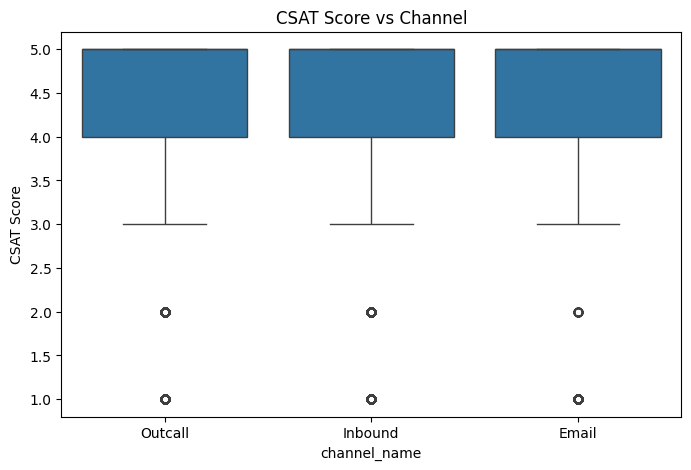

In [37]:
# Chart - 6 visualization code
# CSAT Score vs Channel
plt.figure(figsize=(8,5))
sns.boxplot(x='channel_name', y='CSAT Score', data=df_copy)
plt.title("CSAT Score vs Channel")
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot is used to compare the distribution of CSAT Score across different support channels. It shows median, spread, and outliers effectively.

##### 2. What is/are the insight(s) found from the chart?

* CSAT scores are mostly high (4–5) across all channels.
* No significant difference between Outcall, Inbound, and Email.
* Few low-score outliers exist in every channel.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impact:

* Indicates consistent service quality across channels.

* Helps maintain confidence in current support system.

Negative Insight:

* Presence of low CSAT outliers suggests some poor customer experiences.

* No strong differentiation between channels → improvement opportunities are not channel-specific.

#### Chart - 7

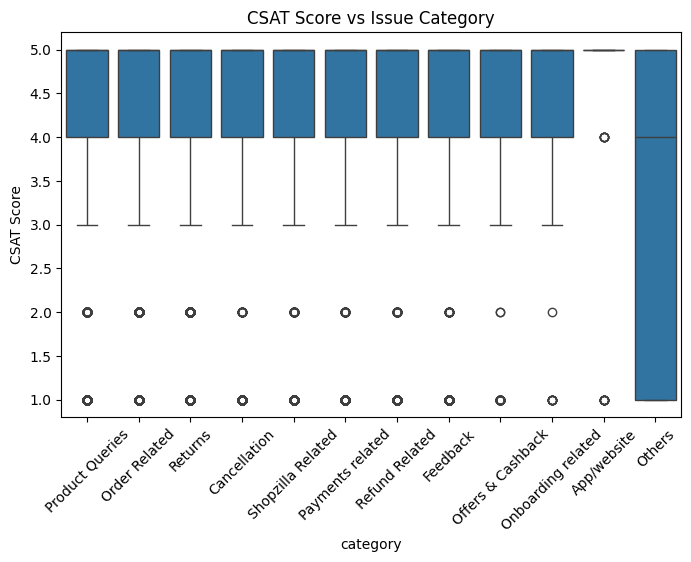

In [38]:
# Chart - 7 visualization code
# CSAT Score vs Issue Category
plt.figure(figsize=(8,5))
sns.boxplot(x='category', y='CSAT Score', data=df_copy)
plt.title("CSAT Score vs Issue Category")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot is used to compare the distribution of CSAT Score across different issue categories. It helps in understanding variation, median scores, and identifying outliers for each category.

##### 2. What is/are the insight(s) found from the chart?

* Most issue categories have high CSAT scores (around 4–5).

* However, low-score outliers (1–2) are present across many categories.

* The “Others” category shows higher variability, indicating inconsistent customer experience.

* No category stands out as extremely poor, but some categories have slightly wider spread, showing inconsistency.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive Impact:**

* Overall high CSAT indicates good customer satisfaction across issue types.

* Helps identify categories where service is stable and performing well.

**Negative Insight:**

* Presence of low CSAT scores across categories indicates unresolved customer pain points.

* High variability (especially in “Others”) suggests lack of standardization in handling certain issues, which may impact customer trust.

#### Chart - 8

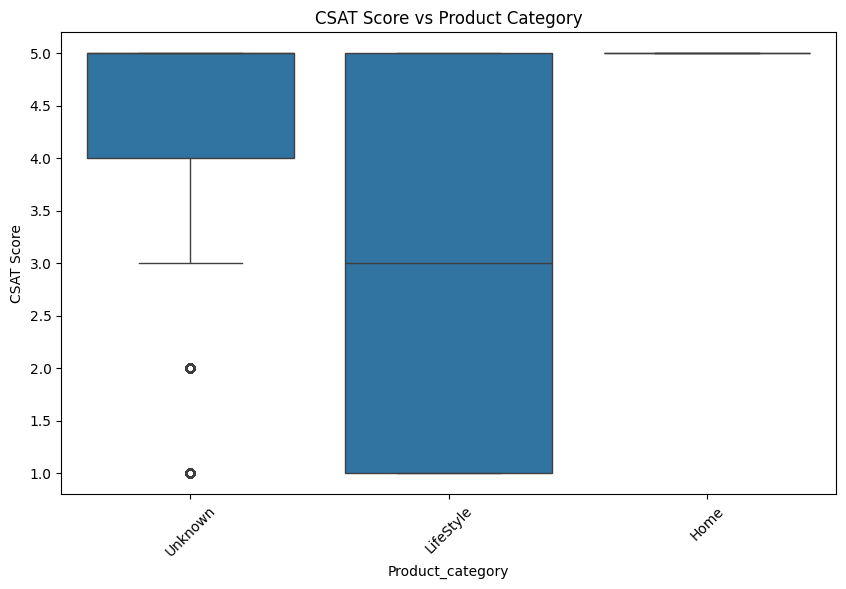

In [39]:
# Chart - 8 visualization code
# CSAT Score vs Product Category
plt.figure(figsize=(10,6))
sns.boxplot(x='Product_category', y='CSAT Score', data=df_copy)
plt.title("CSAT Score vs Product Category")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot is used because it effectively compares the distribution of CSAT scores across different product categories.It helps in identifying median, spread, and outliers for each category, which is important for performance comparison.

##### 2. What is/are the insight(s) found from the chart?

* Home category shows consistently high CSAT scores (mostly around 5), indicating strong customer satisfaction.

* Lifestyle category has a wide spread (1 to 5), meaning customer experience is inconsistent.

* Unknown category also shows variability with some low outliers (scores 1–2), indicating potential issues.

* Lifestyle and Unknown categories have more low ratings compared to Home.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights can help create a positive business impact. The Home category shows consistently high CSAT scores, indicating strong customer satisfaction, which can be leveraged to maintain customer loyalty and increase repeat purchases.

However, there is also an indication of potential negative growth. The Lifestyle category shows a wide variation in CSAT scores, including very low ratings. This inconsistency suggests poor or uneven customer experience, which may lead to customer dissatisfaction, negative reviews, and reduced retention if not improved.

#### Chart - 9

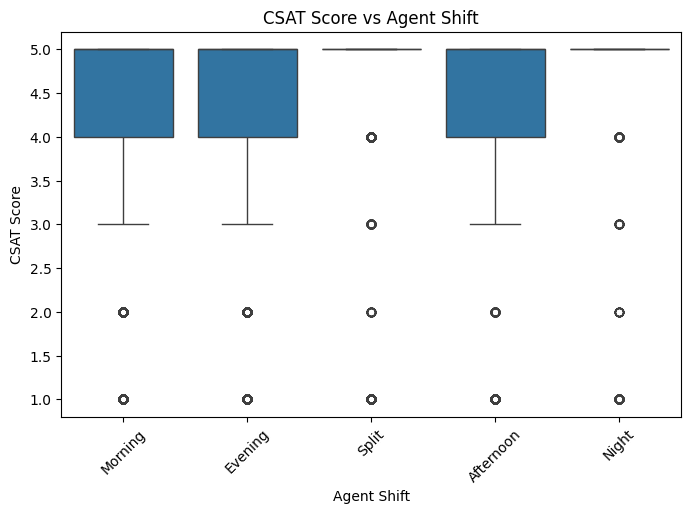

In [40]:
# Chart - 9 visualization code
# CSAT Score vs Agent Shift
plt.figure(figsize=(8,5))
sns.boxplot(x='Agent Shift', y='CSAT Score', data=df_copy)
plt.title("CSAT Score vs Agent Shift")
plt.xticks(rotation=45)
plt.show()



##### 1. Why did you pick the specific chart?

A box plot is used to compare CSAT score distributions across different agent shifts. It helps in identifying differences in median scores, variability, and outliers between shifts.

##### 2. What is/are the insight(s) found from the chart?

* CSAT scores are quite similar across all shifts (Morning, Evening, Night, etc.), mostly ranging between 4 and 5.
* There is no major difference in median satisfaction across shifts.
* However, low-score outliers (1–2) are present in all shifts, indicating occasional poor customer experiences.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights can create a positive business impact as consistent CSAT scores across all shifts indicate uniform service quality, allowing the business to operate efficiently throughout the day without worrying about shift-based performance issues.

However, the presence of low CSAT outliers in every shift indicates occasional service failures. If not addressed, these poor experiences can lead to customer dissatisfaction, negative feedback, and reduced customer retention, which may negatively impact business growth.

#### Chart - 10

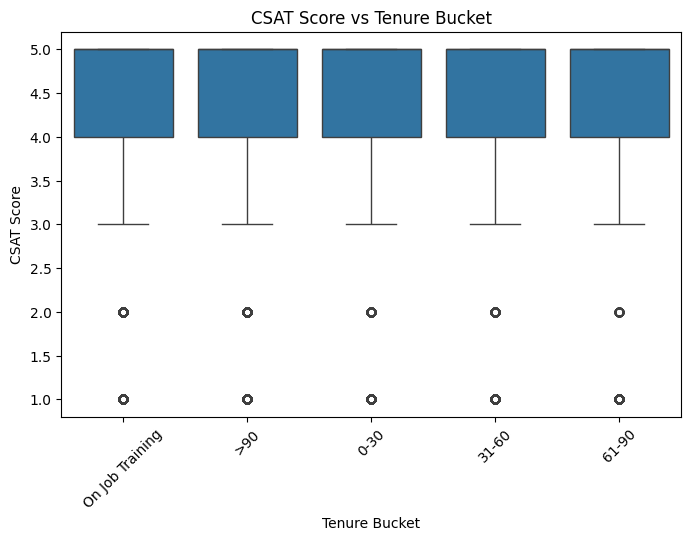

In [41]:
# Chart - 10 visualization code
# CSAT Score vs Tenure Bucket
plt.figure(figsize=(8,5))
sns.boxplot(x='Tenure Bucket', y='CSAT Score', data=df_copy)
plt.title("CSAT Score vs Tenure Bucket")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot was chosen because it is effective for comparing the distribution of CSAT scores across multiple tenure groups. It helps identify variations, median differences, and outliers among different employee experience levels.

##### 2. What is/are the insight(s) found from the chart?

The CSAT scores are almost similar across all tenure buckets, with most values concentrated between 4 and 5. There is no significant difference in customer satisfaction based on agent tenure, indicating consistent performance across experience levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this insight suggests that training programs are effective, as even new agents perform similarly to experienced ones. However, a potential negative insight is that tenure is not contributing to improved performance over time, which may indicate lack of advanced skill development or growth opportunities.

#### Chart - 11

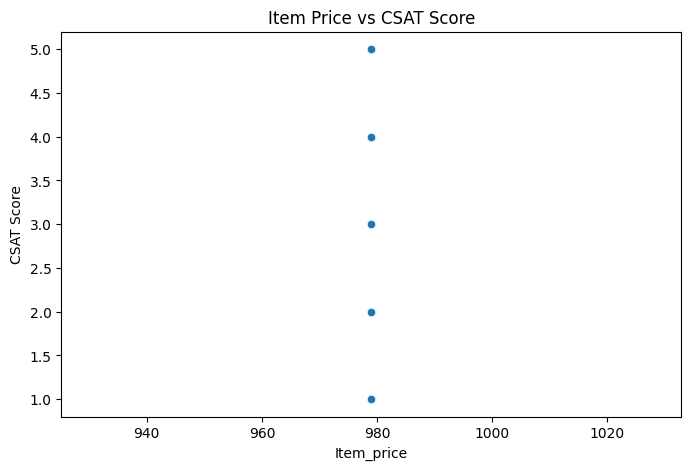

In [42]:
# Chart - 11 visualization code
# Item Price vs CSAT Score
plt.figure(figsize=(8,5))
sns.scatterplot(x='Item_price', y='CSAT Score', data=df_copy)
plt.title("Item Price vs CSAT Score")
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot was chosen to analyze the relationship between item price and CSAT score. It helps in identifying correlations or trends between two continuous variables.

##### 2. What is/are the insight(s) found from the chart?

There is no visible correlation between item price and CSAT score. Prices remain almost constant while CSAT scores vary widely, indicating that price does not influence customer satisfaction in this dataset.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, this insight helps businesses focus more on service quality rather than pricing to improve CSAT. However, the lack of price variation limits deeper analysis and may indicate poor pricing strategy or lack of segmentation, which could negatively impact competitiveness.

#### Chart - 12

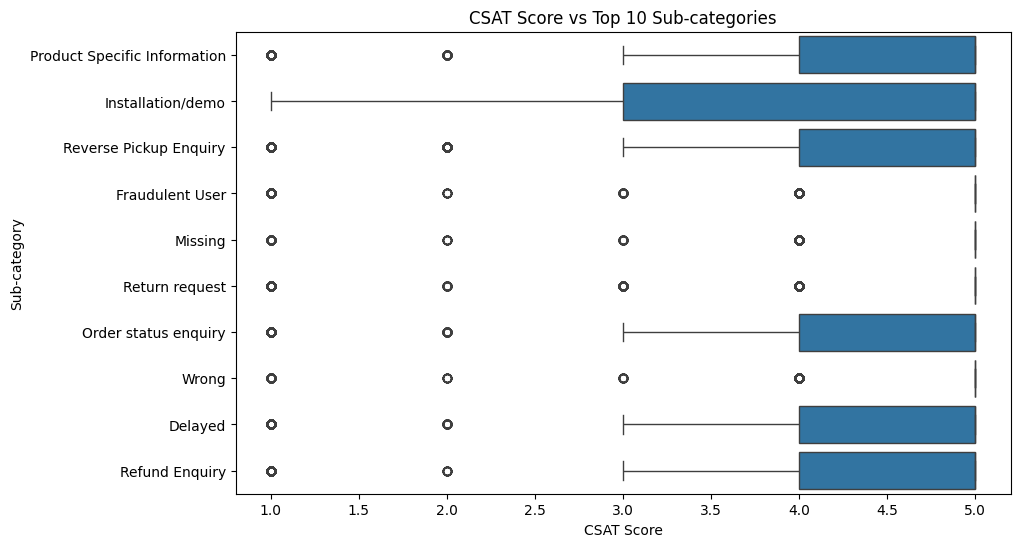

In [43]:
# Chart - 12 visualization code
# CSAT Score vs Sub-category
# Get top 10 most frequent sub-categories
top_subcat = df_copy['Sub-category'].value_counts().head(10).index

# Filter dataset for these sub-categories
df_top = df_copy[df_copy['Sub-category'].isin(top_subcat)]

# Plot the chart
plt.figure(figsize=(10,6))
sns.boxplot(y='Sub-category', x='CSAT Score', data=df_top)
plt.title("CSAT Score vs Top 10 Sub-categories")
plt.xlabel("CSAT Score")
plt.ylabel("Sub-category")
plt.show()

##### 1. Why did you pick the specific chart?

A boxplot was chosen to compare CSAT score distributions across multiple sub-categories. It effectively highlights differences in customer satisfaction levels and identifies problematic areas.

##### 2. What is/are the insight(s) found from the chart?

Certain sub-categories like Installation/demo and Order status enquiry show higher CSAT scores, while Missing, Wrong, and Return request have lower and more spread-out scores. This indicates that issue type significantly impacts customer satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights allow the business to focus on improving weak areas like returns and delivery issues, which can significantly boost overall CSAT. However, consistently low scores in these categories indicate operational inefficiencies, which may lead to customer dissatisfaction and negative growth if not addressed.

#### Chart - 13

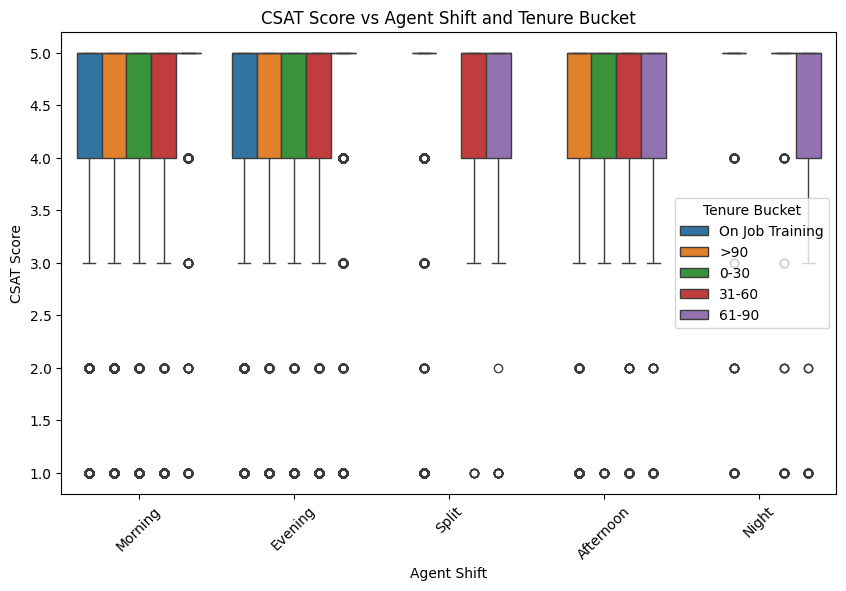

In [44]:
# Chart - 13 visualization code
# CSAT Score vs Agent Shift & Tenure Bucket
plt.figure(figsize=(10,6))
sns.boxplot(x='Agent Shift', y='CSAT Score', hue='Tenure Bucket', data=df_copy)
plt.title("CSAT Score vs Agent Shift and Tenure Bucket")
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

This boxplot was chosen because it effectively shows the distribution of CSAT scores across different agent shifts while also comparing tenure buckets. It helps in understanding variations, median performance, and the presence of outliers, making it suitable for analyzing how shift timing and experience level impact customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

The chart shows that most CSAT scores are concentrated at higher values (around 4–5) across all shifts, indicating generally good performance. However, there are noticeable outliers with low scores in every shift. The distribution across tenure buckets appears similar, suggesting that tenure has limited impact, while slight variations across shifts indicate that certain shifts may experience more inconsistency in performance.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help create a positive business impact by identifying shifts with inconsistent performance and enabling targeted training or resource allocation. However, the presence of low-score outliers across all shifts indicates potential service quality issues, which could negatively impact customer satisfaction if not addressed. Improving consistency, especially in shifts with higher variability, can lead to better overall performance and customer experience.

#### Chart - 14 - Correlation Heatmap

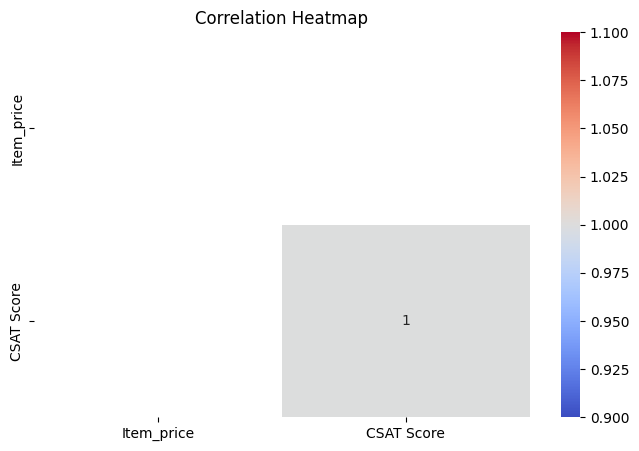

In [45]:
# Correlation Heatmap visualization code
plt.figure(figsize=(8,5))
sns.heatmap(df_copy.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap was chosen to quickly understand the relationship between numerical variables in the dataset. It helps identify whether any features are strongly positively or negatively correlated with the target variable (CSAT Score), which is useful for feature selection and model building.

##### 2. What is/are the insight(s) found from the chart?

The heatmap shows very weak or no significant correlation between the available numerical features (like Item_price) and CSAT Score. This indicates that numerical variables alone are not strong predictors of customer satisfaction, and other categorical or derived features may be more important.

#### Chart - 15 - Pair Plot

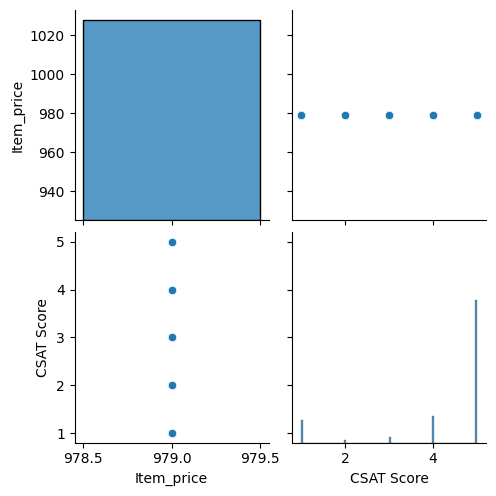

In [46]:
# Pair Plot visualization code
sns.pairplot(df_copy.select_dtypes(include=['int64','float64']))

##### 1. Why did you pick the specific chart?

A pair plot was chosen to visualize the distribution of numerical features and to understand the pairwise relationships between them. It helps in identifying patterns, trends, and potential correlations between variables, as well as detecting outliers in the dataset.

##### 2. What is/are the insight(s) found from the chart?

The pair plot shows that there is no clear linear relationship between Item_price and CSAT Score. The data points are scattered, indicating weak or no correlation. Additionally, the distribution of CSAT Score appears skewed towards higher ratings, suggesting class imbalance. This implies that numerical features alone may not be sufficient to predict customer satisfaction effectively.

## ***5. Preparing the Data for the Model***

The model can only work with numbers, so in this section we will:

1. Turn the CSAT score into a simple **Satisfied / Not satisfied** target
2. Create useful new columns (response time, hour, day)
3. Remove columns the model cannot use
4. Convert text categories into numbers
5. Split the data into a training part and a testing part

### 5.1 Set the Target: Satisfied or Not?

Most customers give a 5, which makes predicting the exact score (1 to 5) difficult. So we group the scores into two simple classes:

* **Satisfied:** CSAT score 4 or 5
* **Not satisfied:** CSAT score 1, 2 or 3

This matches the goal of the project: finding out which support interactions lead to a **high or low** satisfaction score.

Number of interactions:
  Not satisfied (1-3): 10806  (15.7%)
  Satisfied (4-5): 57902  (84.3%)


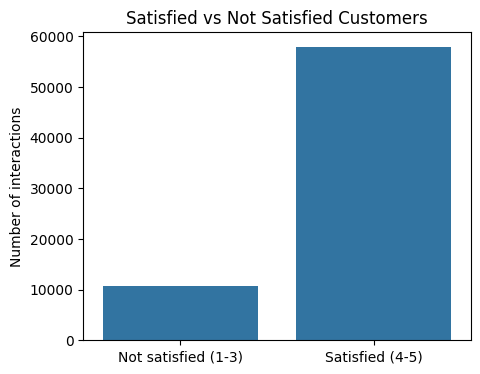


Baseline accuracy (always guess 'Satisfied'): 84.3%


In [47]:
# Create a copy of the cleaned dataset for modeling
df_model = df_copy.copy()

# Create the target column: 1 = Satisfied (4 or 5), 0 = Not satisfied (1, 2 or 3)
df_model['Satisfied'] = (df_model['CSAT Score'] >= 4).astype(int)

# How many customers are in each group?
counts = df_model['Satisfied'].value_counts().sort_index()
labels = ['Not satisfied (1-3)', 'Satisfied (4-5)']
print("Number of interactions:")
for label, value in zip(labels, counts.values):
    print(f"  {label}: {value}  ({value / len(df_model) * 100:.1f}%)")

plt.figure(figsize=(5, 4))
sns.barplot(x=labels, y=counts.values)
plt.title('Satisfied vs Not Satisfied Customers')
plt.ylabel('Number of interactions')
plt.show()

# If a "model" always guessed "Satisfied", how accurate would it be?
baseline_accuracy = counts.max() / counts.sum() * 100
print(f"\nBaseline accuracy (always guess 'Satisfied'): {baseline_accuracy:.1f}%")

**Note:** Most customers are satisfied, so a model that always guesses "Satisfied" would already look accurate. That is why later we also check **how many unhappy customers the model actually catches**, not just overall accuracy.

### 5.2 Create New Columns

The raw dates are not useful to a model, but they hide useful information:

* **response_time_min:** how many minutes the agent took to respond
* **issue_hour:** the hour of the day the issue was reported
* **issue_day:** the day of the week (0 = Monday, 6 = Sunday)

In [48]:
# Check that the date columns are available
needed = ['Issue_reported at', 'issue_responded']
missing = [c for c in needed if c not in df_model.columns]
assert not missing, f"Columns not found: {missing}. Please re-run the data cleaning steps above."

# Response time in minutes
df_model['response_time_min'] = (
    df_model['issue_responded'] - df_model['Issue_reported at']
).dt.total_seconds() / 60

# Time-based columns
df_model['issue_hour'] = df_model['Issue_reported at'].dt.hour
df_model['issue_day'] = df_model['Issue_reported at'].dt.dayofweek

# Clean-up: no negative times, and fill any gaps with the median value
df_model['response_time_min'] = df_model['response_time_min'].clip(lower=0)
for col in ['response_time_min', 'issue_hour', 'issue_day']:
    df_model[col] = df_model[col].fillna(df_model[col].median())

df_model[['response_time_min', 'issue_hour', 'issue_day']].describe().round(1)

,response_time_min,issue_hour,issue_day
count,68708.0,68708.0,68708.0
mean,104.1,14.7,2.8
std,343.9,5.0,2.0
min,0.0,0.0,0.0
25%,2.0,11.0,1.0
50%,5.0,15.0,3.0
75%,26.0,19.0,5.0
max,5729.0,23.0,6.0


### 5.3 Remove Columns the Model Cannot Use and Convert Text to Numbers

* **Removed:** IDs, agent names, customer remarks (free text) and the original date columns. They are either unique to each row or already used to create the new columns above.
* **CSAT Score** is also removed from the inputs, because the target is built from it (keeping it would give the answer away to the model).
* **Text categories** (channel, city, shift and so on) are converted into 0/1 columns. For example, `Agent Shift` becomes `Agent Shift_Morning`, `Agent Shift_Evening`, and so on, with a 1 where it applies.

In [49]:
# Remove columns that are not useful for the model
drop_cols = [
    'Unique id', 'Order_id', 'Agent_name', 'Customer Remarks',
    'Issue_reported at', 'issue_responded', 'Survey_response_Date',
    'CSAT Score'
]
df_model = df_model.drop(columns=[c for c in drop_cols if c in df_model.columns])

# Inputs (X) and target (y)
X_raw = df_model.drop(columns='Satisfied')
y = df_model['Satisfied']

# Convert text categories into 0/1 columns
X = pd.get_dummies(X_raw, drop_first=True, dtype=int)

print("Final input shape:", X.shape)
X.head()

Final input shape: (68708, 140)


,Item_price,response_time_min,issue_hour,issue_day,channel_name_Inbound,channel_name_Outcall,category_Cancellation,category_Feedback,category_Offers & Cashback,category_Onboarding related,...,Manager_Olivia Tan,Manager_William Kim,Tenure Bucket_31-60,Tenure Bucket_61-90,Tenure Bucket_>90,Tenure Bucket_On Job Training,Agent Shift_Evening,Agent Shift_Morning,Agent Shift_Night,Agent Shift_Split
0,979.0,34.0,11,1,0,1,0,0,0,0,...,0,0,0,0,0,1,0,1,0,0
1,979.0,2.0,12,1,0,1,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
2,979.0,22.0,20,1,1,0,0,0,0,0,...,0,1,0,0,0,1,1,0,0,0
3,979.0,20.0,20,1,1,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,0
4,979.0,2.0,10,1,1,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0


### 5.4 Split the Data: Training and Testing

We use **80%** of the data to teach the model and keep **20%** hidden to test it on interactions it has never seen. The split keeps the same share of satisfied and unhappy customers in both parts.

We also put the number columns (price, response time, hour, day) on a similar scale so that the Logistic Regression model treats them fairly.

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Put number columns on the same scale (used for Logistic Regression)
num_cols = ['Item_price', 'response_time_min', 'issue_hour', 'issue_day']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows: 54966
Testing rows:  13742


## ***6. Building the Models***

We will try two models and compare them:

1. **Logistic Regression:** a simple, easy-to-explain model. It acts as our starting point.
2. **Random Forest:** a stronger model that combines many decision trees and can find more complex patterns.

Because unhappy customers are the minority, both models are told to give them extra attention (`class_weight='balanced'`), otherwise they would simply ignore them.

**How we will judge the models:**

* **Accuracy:** how often the model is right overall.
* **Unhappy customers caught:** out of all truly unhappy customers, how many the model found. This matters most for the business.
* **Correct "unhappy" alerts:** when the model says a customer is unhappy, how often it is right.
* **Balance score:** one number that combines the two points above.

In [51]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Store the results of every model here
results = {}
predictions = {}

def evaluate_model(name, y_true, y_pred):
    # "Not satisfied" is class 0, so that is the class we focus on
    results[name] = {
        'Accuracy (%)': accuracy_score(y_true, y_pred) * 100,
        'Unhappy customers caught (%)': recall_score(y_true, y_pred, pos_label=0) * 100,
        'Correct unhappy alerts (%)': precision_score(y_true, y_pred, pos_label=0, zero_division=0) * 100,
        'Balance score (%)': f1_score(y_true, y_pred, pos_label=0) * 100,
    }
    predictions[name] = y_pred
    print(f"{name}")
    for metric, value in results[name].items():
        print(f"  {metric}: {value:.1f}")

### 6.1 Model 1: Logistic Regression

In [52]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)
evaluate_model('Logistic Regression', y_test, y_pred_log)

Logistic Regression
  Accuracy (%): 60.3
  Unhappy customers caught (%): 64.9
  Correct unhappy alerts (%): 23.0
  Balance score (%): 33.9


### 6.2 Model 2: Random Forest

In [53]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=10,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
evaluate_model('Random Forest', y_test, y_pred_rf)

Random Forest
  Accuracy (%): 67.2
  Unhappy customers caught (%): 59.8
  Correct unhappy alerts (%): 26.2
  Balance score (%): 36.4


### 6.3 Comparing the Models

,Accuracy (%),Unhappy customers caught (%),Correct unhappy alerts (%),Balance score (%)
Logistic Regression,60.3,64.9,23.0,33.9
Random Forest,67.2,59.8,26.2,36.4


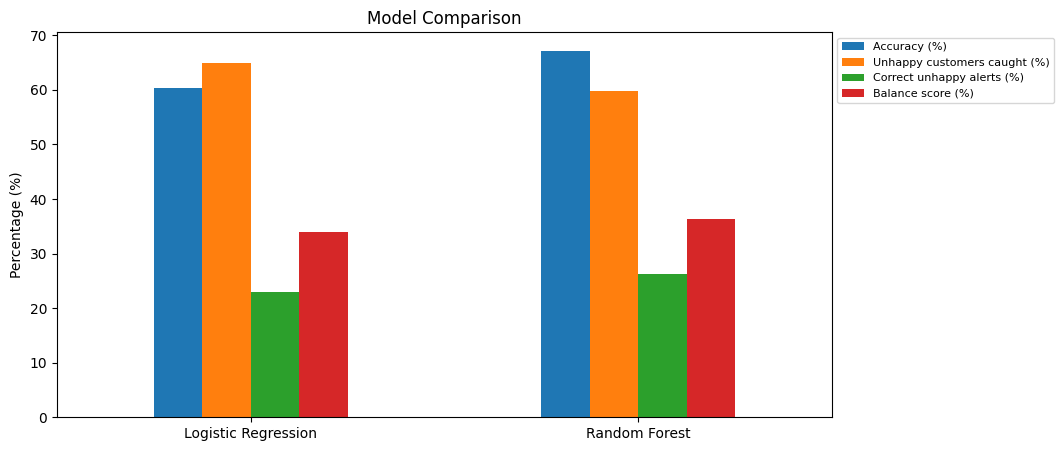

Best model: Random Forest


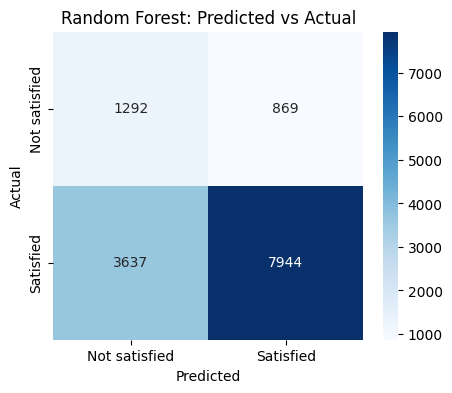

In [55]:
comparison = pd.DataFrame(results).T.round(1)
display(comparison)

# Chart
comparison.plot(kind='bar', figsize=(10, 5), rot=0)
plt.title('Model Comparison')
plt.ylabel('Percentage (%)')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=8)
plt.show()

# Pick the best model: the one that finds unhappy customers best without too many false alarms
best_model_name = comparison['Balance score (%)'].idxmax()
print("Best model:", best_model_name)

# Confusion matrix for the best model
cm = confusion_matrix(y_test, predictions[best_model_name])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not satisfied', 'Satisfied'],
            yticklabels=['Not satisfied', 'Satisfied'])
plt.title(f'{best_model_name}: Predicted vs Actual')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**How to read the chart above:** each box counts customers. The diagonal boxes (top-left and bottom-right) are correct predictions. The off-diagonal boxes are mistakes.

##### Which model is chosen and why?
Random Forest is selected because it has the highest **Balance score** (36.4%). Logistic Regression catches slightly more unhappy customers, but it raises many more false alarms and has lower accuracy. Random Forest gives the best trade-off between the two. Overall accuracy alone would be misleading, since most customers are satisfied anyway.

##### Business impact
Support managers can use this model to **spot interactions at risk of an unhappy customer** and step in early (for example with a follow-up call or a faster response), instead of waiting for a bad survey score.

## ***7. What Affects Customer Satisfaction?***

The model also tells us **which factors it relied on the most**. This is the main business insight of the project.

Since categories like Manager or City were split into many 0/1 columns, we first add them back together so each factor is shown once.

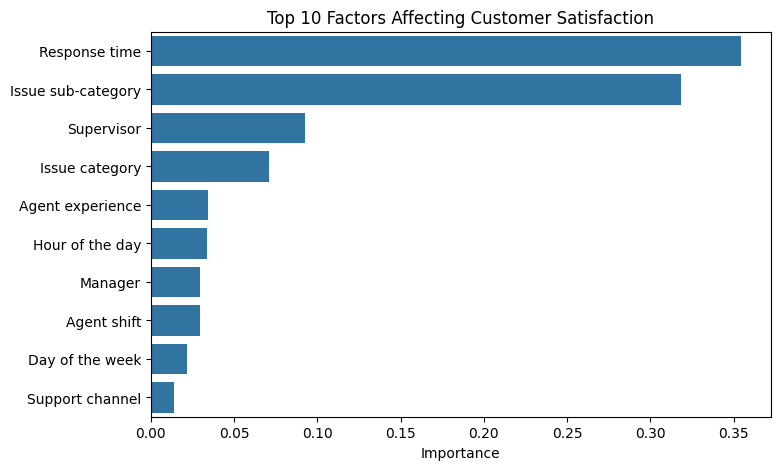

Top 3 factors: Response time, Issue sub-category, Supervisor


In [56]:
# Importance score of every column, from the Random Forest
importance = pd.Series(rf_model.feature_importances_, index=X.columns)

# Add the 0/1 columns back to their original factor (e.g. all Manager_* columns -> Manager)
cat_cols = X_raw.select_dtypes(exclude='number').columns.tolist()

def original_name(col):
    matches = [c for c in cat_cols if col.startswith(c + '_')]
    return max(matches, key=len) if matches else col

grouped = importance.groupby(original_name).sum().sort_values(ascending=False)

# Friendlier names for the chart
nice_names = {
    'response_time_min': 'Response time',
    'issue_hour': 'Hour of the day',
    'issue_day': 'Day of the week',
    'channel_name': 'Support channel',
    'category': 'Issue category',
    'Sub-category': 'Issue sub-category',
    'Customer_City': 'Customer city',
    'Product_category': 'Product category',
    'Item_price': 'Item price',
    'Agent Shift': 'Agent shift',
    'Tenure Bucket': 'Agent experience',
}
top10 = grouped.head(10).rename(index=lambda x: nice_names.get(x, x))

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index)
plt.title('Top 10 Factors Affecting Customer Satisfaction')
plt.xlabel('Importance')
plt.ylabel('')
plt.show()

print("Top 3 factors:", ", ".join(top10.index[:3]))

### How do the top factors relate to unhappy customers?

The charts below show the **percentage of unhappy customers (CSAT 1-3)** for different situations.

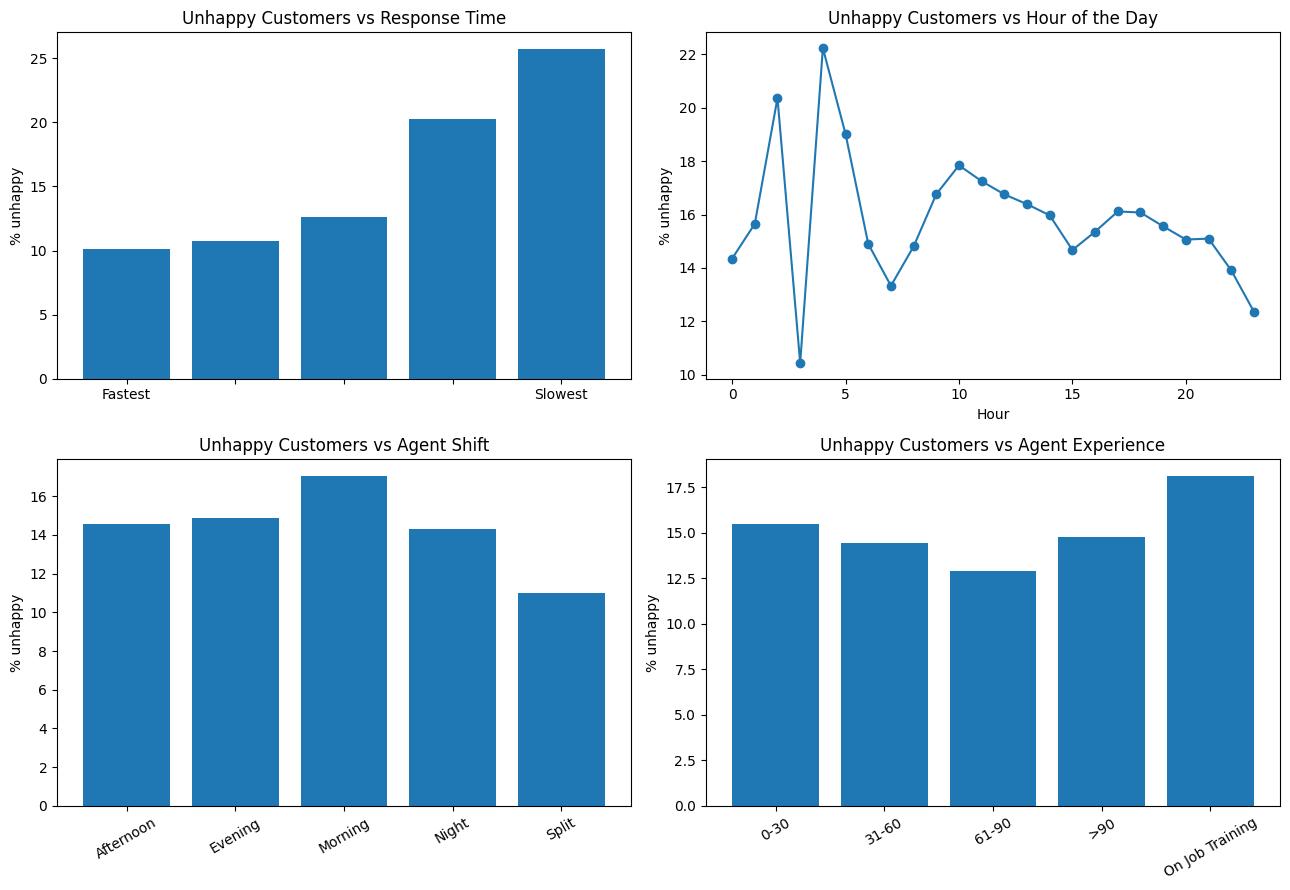

In [57]:
# Percentage of unhappy customers in a group
def unhappy_rate(s):
    return (1 - s.mean()) * 100

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Response time (customers split into 5 equal groups, fastest to slowest)
resp_groups = pd.qcut(df_model['response_time_min'], 5, duplicates='drop')
rt = df_model.groupby(resp_groups, observed=True)['Satisfied'].apply(unhappy_rate)
axes[0, 0].bar(range(len(rt)), rt.values)
axes[0, 0].set_xticks(range(len(rt)))
axes[0, 0].set_xticklabels(['Fastest'] + [''] * (len(rt) - 2) + ['Slowest'] if len(rt) > 1 else ['All'])
axes[0, 0].set_title('Unhappy Customers vs Response Time')
axes[0, 0].set_ylabel('% unhappy')

# 2. Hour of the day
hr = df_model.groupby('issue_hour')['Satisfied'].apply(unhappy_rate)
axes[0, 1].plot(hr.index, hr.values, marker='o')
axes[0, 1].set_title('Unhappy Customers vs Hour of the Day')
axes[0, 1].set_xlabel('Hour')
axes[0, 1].set_ylabel('% unhappy')

# 3. Agent shift
sh = df_model.groupby('Agent Shift')['Satisfied'].apply(unhappy_rate)
axes[1, 0].bar(sh.index, sh.values)
axes[1, 0].set_title('Unhappy Customers vs Agent Shift')
axes[1, 0].set_ylabel('% unhappy')
axes[1, 0].tick_params(axis='x', rotation=30)

# 4. Agent experience
tn = df_model.groupby('Tenure Bucket')['Satisfied'].apply(unhappy_rate)
axes[1, 1].bar(tn.index, tn.values)
axes[1, 1].set_title('Unhappy Customers vs Agent Experience')
axes[1, 1].set_ylabel('% unhappy')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### What the Charts Show

* **Response time:** the slower the reply, the more unhappy customers. About 10% of customers with the fastest responses are unhappy, compared with about 26% for the slowest responses.
* **Agent experience:** agents still in on-the-job training have the highest share of unhappy customers (about 18%). There is no steady improvement as experience grows, so experience alone is not the main driver.
* **Agent shift:** the morning shift has the highest share of unhappy customers (about 17%), and the split shift has the lowest (about 11%).
* **Hour of the day:** the share of unhappy customers changes a lot in the early hours (0 to 5) but stays fairly steady during the day, so the hour is not a clear driver on its own.

### Business Recommendations

1. **Respond faster.** Response time is the strongest driver of satisfaction, so setting response-time targets and tracking them daily will help the most.
2. **Focus on the problem issue types.** Issue sub-category is the second strongest factor, so find the issue types with the most unhappy customers and give agents clear guides and training for them.
3. **Learn from the best teams.** Supervisor is the third strongest factor, which points to differences between teams. Sharing the practices of the best-performing teams can raise satisfaction everywhere.
4. **Support agents in training and the morning shift.** Mentoring for agents still in training and extra support for the morning shift can reduce unhappy customers.
5. **Use the model as an early-warning tool.** Flag interactions that look like they will end in an unhappy customer and follow up before the survey is sent.

# **Conclusion**

In [58]:
# Final summary, generated from the results above
best = results[best_model_name]

print("PROJECT SUMMARY")
print("-" * 45)
print(f"Interactions analysed        : {len(df_model)}")
print(f"Satisfied customers          : {y.mean() * 100:.1f}%")
print(f"Not satisfied customers      : {(1 - y.mean()) * 100:.1f}%")
print(f"Best model                   : {best_model_name}")
print(f"Overall accuracy             : {best['Accuracy (%)']:.1f}%")
print(f"Unhappy customers caught     : {best['Unhappy customers caught (%)']:.1f}%")
print(f"Top 3 factors                : {', '.join(top10.index[:3])}")
print(f"Unhappy (fastest responses)  : {rt.iloc[0]:.1f}%")
print(f"Unhappy (slowest responses)  : {rt.iloc[-1]:.1f}%")

PROJECT SUMMARY
---------------------------------------------
Interactions analysed        : 68708
Satisfied customers          : 84.3%
Not satisfied customers      : 15.7%
Best model                   : Random Forest
Overall accuracy             : 67.2%
Unhappy customers caught     : 59.8%
Top 3 factors                : Response time, Issue sub-category, Supervisor
Unhappy (fastest responses)  : 10.1%
Unhappy (slowest responses)  : 25.7%


### Objective
The goal of this project was to understand what drives customer satisfaction (CSAT) in an e-commerce support team, and to predict which support interactions are likely to end with an unhappy customer.

### What We Did
* Cleaned and explored **68,708** support interactions using charts.
* Created useful new columns such as **response time**, **hour of the day** and **day of the week**.
* Grouped CSAT scores into **Satisfied (4-5)** and **Not satisfied (1-3)**. About 84% of customers were satisfied and about 16% were not.
* Trained two models, **Logistic Regression** and **Random Forest**, and compared them.

### Model Results
**Random Forest** was the best model. It was right 67% of the time overall and found about 60% of the unhappy customers. Because most customers are satisfied, we judged the models by how many unhappy customers they catch and how often their alerts are correct, not by accuracy alone.

### Key Findings
* **Response time is the biggest driver.** About 10% of customers with the fastest responses were unhappy, compared with about 26% for the slowest responses.
* **The type of issue matters.** Issue sub-category and issue category were among the top factors, so some issue types upset customers more than others.
* **The supervisor matters.** It was the third most important factor, which points to differences between teams.
* **Agent experience and shift play a smaller role.** Agents still in on-the-job training (about 18%) and the morning shift (about 17%) had the most unhappy customers.
* **Hour and day have little effect on their own.** The share of unhappy customers stays fairly steady during the day.

### Business Recommendations
1. Set and track response-time targets, because faster replies lead to happier customers.
2. Give agents better guides and training for the issue types with the most unhappy customers.
3. Share the practices of the best-performing supervisors and teams.
4. Support agents in training and the morning shift with mentoring.
5. Use the model as an early-warning tool to flag at-risk interactions and follow up before the survey is sent.

### Limitations and Next Steps
The model finds only part of the unhappy customers, because satisfaction also depends on things that are not in the data, such as the customer's mood or how complicated the issue was. Adding the **customer remarks (text feedback)** and resolution details would likely improve the results.